# Issuer credit and funding research

**Amendment declared 18 October 2026:** generalize the previous issuer-specific replay into a reusable, case-configured diagnostic. The issuer, bond identifiers, equity symbols, monetary units, disclosure timezone, data snapshot, quorum and horizons now come from a separate case file. CoreWeave is the retained historical case, not a hard-coded model or a classifier for future companies. The frozen portfolio notebooks, earlier credit/funding notebook/model, protocols and paper journal remain unchanged.

**Review fixes:** reject duplicate bonds, mixed issuers, invalid diagnostic states, boolean prices/yields, bad dates and invalid rule settings; handle empty panels and no-warning cases; retain different fiscal periods and dated revisions; verify bond ownership and all evidence hashes. Results and chart labels are computed from the selected case instead of copied historical conclusions. A staged-checkout check found Git line-ending differences in supporting text; explicitly declared canonical-LF digests permit those text-only differences. Frozen code, data and notebooks still require exact bytes, and both existing local copies remain byte-unchanged.

Use this framework to investigate capital-intensive issuers whose investments depend on continuing debt/equity funding, collateral-backed borrowing or concentrated contract receipts. A company is not classified as vulnerable merely because it resembles the example. Inspect its own dated evidence, cash restrictions, funding access and contrary evidence.

**Evidence boundary:** current-vintage last-sale yields are not option-adjusted spreads. They can reflect rates, optionality, liquidity and trade composition. Trade dates are not verified historical delivery times. Multiple bonds of one issuer are not independent issuers or matched credit peers. This notebook cannot establish default probability, actionable sell timing or trading advantage. The original qualified OAS gate stays separate.


Selected case: **CoreWeave** (`coreweave_20261017`). Configuration: `research/credit_funding/cases/coreweave_20261017.json`. The generic calculations below contain no issuer-specific symbols or conclusions.

In [1]:
"""Issuer-scoped funding and yield diagnostics; never a qualified OAS signal."""
from datetime import date, datetime, timedelta
import re
import hashlib
import json
from pathlib import Path
from urllib.parse import urlparse
from zoneinfo import ZoneInfo
import numpy as np
import pandas as pd

DIAGNOSTIC_COLUMNS = ['issuer', 'cusip', 'date', 'yield_pct', 'state',
                      'baseline_yield_pct', 'minimum_widening_bp']
TIMELINE_COLUMNS = ['date', 'eligible_bonds', 'warning_bonds', 'state', 'onset_or_resumption']


def inside(root, relative):
    """Case references are repository-relative, with no path escape."""
    root = Path(root).resolve()
    if not isinstance(relative, str) or not relative or Path(relative).is_absolute():
        raise ValueError('Expected relative evidence path')
    path = (root/relative).resolve()
    if not path.is_relative_to(root):
        raise ValueError('Evidence path escapes its root')
    return path


def verify_preserved(root, manifest, case):
    """Allow declared Git line-ending changes only for supporting text files.

    Mathematical code, notebooks and data always require their exact byte hashes.
    The canonical LF digest must be recorded explicitly in the case declaration.
    """
    preserved = manifest.get('preserved_project_sha256',{})
    canonical = case.get('preserved_text_lf_sha256',{})
    for name in canonical:
        if name not in preserved or not (name == '.gitattributes' or Path(name).suffix in {'.md','.txt','.bat','.command'}):
            raise ValueError('Text normalization is forbidden for this frozen artifact')
    for name, expected in preserved.items():
        raw = inside(root,name).read_bytes()
        if hashlib.sha256(raw).hexdigest() == expected:
            continue
        if name in canonical and hashlib.sha256(raw.replace(b'\r\n',b'\n')).hexdigest() == canonical[name]:
            continue
        raise ValueError('Preserved project changed: '+name)


def load_case(root, case_path):
    """Verify immutable evidence and issuer ownership before calculating a case."""
    root = Path(root).resolve()
    case = json.loads(inside(root, case_path).read_text(encoding='utf-8'))
    if not re.fullmatch(r'[a-z0-9_-]+', case.get('case_id','')):
        raise ValueError('Case id must be a safe lowercase identifier')
    spec = dict(case['rules'], issuer=case['issuer'], bonds=case['bonds'], bond_window=case['bond_window'])
    validate_spec(spec)
    ZoneInfo(case['reporting_timezone'])
    if not re.fullmatch(r'[A-Z]{3} millions', case['units']) or case['units'].split()[0] != case['bond_currency']:
        raise ValueError('Case requires one declared monetary currency; no implicit FX conversion')
    data = inside(root, case['evidence_dir'])
    manifest_path = data/'manifest.json'
    if hashlib.sha256(manifest_path.read_bytes()).hexdigest() != case['evidence_manifest_sha256']:
        raise ValueError('Evidence manifest changed')
    manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
    required = {'bond_daily.csv','equity_adjusted.csv','funding_disclosures.json','instruments.json'}
    if not required.issubset(manifest['file_sha256']):
        raise ValueError('Case inputs must all be pinned in the evidence manifest')
    for name, expected in manifest['file_sha256'].items():
        if hashlib.sha256(inside(data,name).read_bytes()).hexdigest() != expected:
            raise ValueError('Evidence changed: '+name)
    verify_preserved(root,manifest,case)
    if 'source_spec_sha256' in manifest:
        prior = inside(root, case['prior_spec_path'])
        if hashlib.sha256(prior.read_bytes()).hexdigest() != manifest['source_spec_sha256']:
            raise ValueError('Prior case specification changed')
    instruments = pd.DataFrame(json.loads((data/'instruments.json').read_text(encoding='utf-8')))
    if not {'cusip','issuerName'}.issubset(instruments) or instruments.cusip.duplicated().any():
        raise ValueError('Invalid instrument ownership table')
    selected = instruments.loc[instruments.cusip.isin(case['bonds'])].copy()
    if set(selected.cusip) != set(case['bonds']) or not selected.issuerName.eq(case['bond_issuer_name']).all():
        raise ValueError('Bond ownership does not match declared issuer')
    bonds = pd.read_csv(data/'bond_daily.csv',dtype={'cusip':str})
    equity = pd.read_csv(data/'equity_adjusted.csv',index_col=0,parse_dates=True)
    if set(equity.columns) != set(case['equity_symbols']) or case['issuer'] not in equity.columns:
        raise ValueError('Equity panel does not match case symbols')
    equity = equity[case['equity_symbols']]
    funding = json.loads((data/'funding_disclosures.json').read_text(encoding='utf-8'))
    return case, spec, manifest, selected, bonds, equity, funding


def positive_int(value, name):
    if isinstance(value, bool) or not isinstance(value, int) or value < 1:
        raise ValueError(f'{name} must be a positive integer')
    return value


def iso_date(value):
    if not isinstance(value, str) or not re.fullmatch(r'\d{4}-\d{2}-\d{2}', value):
        raise ValueError('Expected YYYY-MM-DD date, without an intraday time')
    return date.fromisoformat(value)


def daily_index(values, unique=True):
    result = pd.DatetimeIndex(pd.to_datetime(values, errors='raise'))
    if result.tz is not None or result.hasnans or (result != result.normalize()).any():
        raise ValueError('Expected timezone-naive daily session dates')
    if unique and result.has_duplicates:
        raise ValueError('Duplicate session date')
    return result


def validate_spec(spec):
    if not isinstance(spec.get('issuer'), str) or not spec['issuer'].strip():
        raise ValueError('Case issuer is required')
    bonds = spec.get('bonds')
    if not isinstance(bonds, list) or not bonds or any(not isinstance(b, str) or not b.strip() for b in bonds):
        raise ValueError('Declare nonempty instrument identifiers')
    if len(bonds) != len(set(bonds)):
        raise ValueError('Duplicate configured instrument')
    for key in ('history', 'persistence', 'max_gap_calendar_days', 'min_warning_bonds'):
        positive_int(spec.get(key), key)
    if spec['min_warning_bonds'] > len(bonds):
        raise ValueError('Warning quorum exceeds configured instruments')
    threshold = spec.get('widening_bp')
    if isinstance(threshold, bool) or not isinstance(threshold, (int, float)) or not np.isfinite(threshold) or threshold <= 0:
        raise ValueError('Widening threshold must be positive finite basis points')
    window = spec.get('bond_window')
    if not isinstance(window, list) or len(window) != 2 or iso_date(window[0]) > iso_date(window[1]):
        raise ValueError('Invalid bond window')


def funding_timeline(records, *, issuer, units, reporting_timezone):
    """One issuer/currency; preserve periods and revisions as dated disclosures.

    This returns disclosure events, not a carried-forward current funding state.
    Eligibility is the following local midnight, not measured historical receipt.
    """
    if not issuer or not re.fullmatch(r'[A-Z]{3} millions', units):
        raise ValueError('Declare issuer and units such as USD millions')
    zone = ZoneInfo(reporting_timezone)
    result, seen = [], set()
    for r in records:
        if r['issuer'] != issuer or r['units'] != units:
            raise ValueError('Mixed issuer or monetary units')
        start, end, filed = [iso_date(r[k]) for k in ('period_start', 'period_end', 'filed_on')]
        identity = (start, end, filed)
        if start > end or end > filed or identity in seen:
            raise ValueError('Invalid or duplicate financial disclosure')
        seen.add(identity)
        url = urlparse(r['source_url'])
        if url.scheme != 'https' or not url.hostname:
            raise ValueError('Missing public HTTPS disclosure source')
        values = [r[k] for k in ('cash_capex', 'operating_cash_flow', 'debt_principal')]
        if any(isinstance(x, bool) or not isinstance(x, (int, float)) or not np.isfinite(x) for x in values):
            raise ValueError('Invalid monetary input')
        if r['cash_capex'] < 0 or r['debt_principal'] < 0:
            raise ValueError('Cash capex and principal must be nonnegative')
        available = datetime.combine(filed + timedelta(days=1), datetime.min.time(), tzinfo=zone)
        gap = r['cash_capex'] - r['operating_cash_flow']
        result.append(dict(issuer=issuer, period_start=start.isoformat(), period_end=end.isoformat(),
                           period=r['period_label'], eligible_at=available.isoformat(),
                           historical_gap=gap, debt_principal=r['debt_principal'], units=units,
                           state='FUNDING_VULNERABILITY' if gap > 0 and r['debt_principal'] > 0 else 'NO_FLAG',
                           source_url=r['source_url']))
    columns = ['issuer','period_start','period_end','period','eligible_at','historical_gap',
               'debt_principal','units','state','source_url']
    return pd.DataFrame(result, columns=columns).sort_values(['eligible_at','period_end','period_start']).reset_index(drop=True)


def bond_diagnostics(frame, spec):
    """Trade-date diagnostics only. Missing prices/yields invalidate their windows."""
    validate_spec(spec)
    f = frame.copy()
    required = {'cusip', 'tradeDate', 'lastSalePrice', 'lastSaleYield'}
    if not required.issubset(f):
        raise ValueError('Missing TRACE columns')
    if 'issuer' in f and not f['issuer'].eq(spec['issuer']).all():
        raise ValueError('Mixed issuer panel')
    f['tradeDate'] = daily_index(f['tradeDate'], unique=False)
    if f.duplicated(['cusip', 'tradeDate']).any():
        raise ValueError('Duplicate instrument-day')
    if not set(f.cusip).issubset(spec['bonds']):
        raise ValueError('Unexpected instrument')
    if (f.tradeDate < pd.Timestamp(spec['bond_window'][0])).any() or (f.tradeDate > pd.Timestamp(spec['bond_window'][1])).any():
        raise ValueError('Observation outside declared window')
    for col in ('lastSalePrice', 'lastSaleYield'):
        if f[col].map(lambda x: isinstance(x, (bool, np.bool_))).any():
            raise ValueError('Boolean price/yield is invalid')
        f[col] = pd.to_numeric(f[col], errors='raise')
        if np.isinf(f[col]).any() or (col == 'lastSalePrice' and (f[col] <= 0).any()):
            raise ValueError('Invalid price or yield')
    n, p = spec['history'], spec['persistence']
    out = []
    for cusip, g in f.groupby('cusip'):
        g = g.sort_values('tradeDate').reset_index(drop=True)
        for i, row in g.iterrows():
            item = dict(issuer=spec['issuer'], cusip=cusip, date=row.tradeDate, yield_pct=row.lastSaleYield,
                        state='UNKNOWN', baseline_yield_pct=np.nan, minimum_widening_bp=np.nan)
            if i + 1 >= n + p:
                window = g.iloc[i + 1 - n - p:i + 1]
                if (not window[['lastSalePrice','lastSaleYield']].isna().any().any()
                        and window.tradeDate.diff().dropna().dt.days.max() <= spec['max_gap_calendar_days']):
                    baseline = window.lastSaleYield.iloc[:n].median()
                    widening = (window.lastSaleYield.iloc[n:] - baseline) * 100
                    item.update(baseline_yield_pct=baseline, minimum_widening_bp=widening.min(),
                                state='YIELD_WARNING_DIAGNOSTIC' if (widening >= spec['widening_bp']).all() else 'NO_FLAG')
            out.append(item)
    return pd.DataFrame(out, columns=DIAGNOSTIC_COLUMNS).sort_values(['date','cusip']).reset_index(drop=True)


def issuer_timeline(diagnostics, session_dates, spec):
    """Count distinct same-day bonds from one declared issuer; never fill prints."""
    validate_spec(spec)
    d = diagnostics.copy()
    if not set(DIAGNOSTIC_COLUMNS).issubset(d):
        raise ValueError('Missing diagnostic columns')
    d['date'] = daily_index(d['date'], unique=False)
    if d.duplicated(['cusip','date']).any():
        raise ValueError('Duplicate diagnostic instrument-day')
    if not d['issuer'].eq(spec['issuer']).all() or not set(d.cusip).issubset(spec['bonds']):
        raise ValueError('Diagnostic issuer/instrument mismatch')
    if not d.state.isin(['UNKNOWN','NO_FLAG','YIELD_WARNING_DIAGNOSTIC']).all():
        raise ValueError('Invalid diagnostic state')
    rows = []
    for session in daily_index(session_dates).sort_values():
        day = d.loc[d.date == session]
        flags = int((day.state == 'YIELD_WARNING_DIAGNOSTIC').sum())
        known = int((day.state != 'UNKNOWN').sum())
        quorum = spec['min_warning_bonds']
        state = 'YIELD_WARNING_DIAGNOSTIC' if flags >= quorum else ('NO_QUORUM' if known >= quorum else 'UNKNOWN')
        rows.append(dict(date=session, eligible_bonds=known, warning_bonds=flags, state=state))
    timeline = pd.DataFrame(rows, columns=TIMELINE_COLUMNS[:-1])
    timeline['onset_or_resumption'] = (timeline.state == 'YIELD_WARNING_DIAGNOSTIC') & (timeline.state.shift() != 'YIELD_WARNING_DIAGNOSTIC')
    return timeline


def equity_context(timeline, equity, horizons=(5, 20)):
    """Forward changes over observed rows, not executable or calendar-day returns."""
    if not horizons or len(horizons) != len(set(horizons)):
        raise ValueError('Declare unique positive session horizons')
    for horizon in horizons:
        positive_int(horizon, 'horizon')
    prices = equity.copy()
    prices.index = daily_index(prices.index)
    prices = prices.sort_index()
    if prices.columns.has_duplicates or any(not isinstance(c,str) or not c for c in prices.columns):
        raise ValueError('Equity symbol columns must be unique strings')
    if prices.isna().any().any() or any(prices[c].map(lambda x: isinstance(x,(bool,np.bool_))).any() for c in prices):
        raise ValueError('Invalid equity panel; do not fill missing prices')
    try:
        prices = prices.apply(pd.to_numeric, errors='raise')
        if not np.isfinite(prices.to_numpy(dtype=float)).all() or (prices <= 0).any().any():
            raise ValueError('Equity prices must be positive and finite')
    except (TypeError, ValueError) as exc:
        raise ValueError('Invalid equity prices') from exc
    if not {'date','onset_or_resumption'}.issubset(timeline):
        raise ValueError('Missing timeline columns')
    daily_index(timeline.date)
    if not timeline.onset_or_resumption.map(lambda x:isinstance(x,(bool,np.bool_))).all():
        raise ValueError('Onset flags must be boolean')
    columns = ['date'] + [f'{s}_{h}_sessions_pct' for s in prices.columns for h in horizons]
    rows = []
    for session in pd.to_datetime(timeline.loc[timeline.onset_or_resumption, 'date']):
        if session not in prices.index:
            raise ValueError('Missing event-date equity price')
        pos = prices.index.get_loc(session)
        r = dict(date=session)
        for symbol in prices.columns:
            for horizon in horizons:
                r[f'{symbol}_{horizon}_sessions_pct'] = (100 * (prices.iloc[pos+horizon][symbol] / prices.iloc[pos][symbol] - 1)
                    if pos+horizon < len(prices) else np.nan)
        rows.append(r)
    return pd.DataFrame(rows, columns=columns)


In [2]:
from IPython.display import display
from review_checks import verify_review_snapshot
ROOT=Path.cwd()
CASE_PATH='research/credit_funding/cases/coreweave_20261017.json'
EXPECTED_CASE_SHA='cb6b50f4af1c896bb706d23d49f5c48e3e5cf7467c4639f1588ec8753e216867'
if hashlib.sha256(inside(ROOT,CASE_PATH).read_bytes()).hexdigest()!=EXPECTED_CASE_SHA:
    raise ValueError('Case configuration changed; generate a newly declared run')
case,spec,manifest,instruments,bonds,equity,funding=load_case(ROOT,CASE_PATH)
print(verify_review_snapshot())
display(pd.Series(spec).to_frame('Declared rule'))
display(instruments)
display(pd.Series({'case':case['case_id'],'bond_rows':len(bonds),'missing_yields':int(bonds.lastSaleYield.isna().sum()),
    'bond_history_through':bonds.tradeDate.max() if len(bonds) else None,
    'equity_history_through':str(equity.index.max().date()) if len(equity) else None,
    'evidence_created_at':manifest.get('created_at'),'monetary_units':case['units']}).to_frame('Coverage'))
for note in case.get('case_notes',[]): print(note)


{'baseline_sha256': 'a1924728765f10d91d7620054e5d2e604e1b3df3f47b872c74fefce41c85d244', 'parent_protocol_sha256': '97226bad70fc261537536322b6450d36379c8a389b99bd52642f58a3cea59bf2', 'paper_protocol_sha256': '6cad006a15f77ffd19fa5147e3262f1693b8edf68f13a20de980e8653a05a536', 'journal_head_sha256': '5808c1f3bcfb7c85202cd42ab552675f6605f3d2c4d9a1bb0d27b80a16cfdc66', 'journal_entries': 1, 'status': 'VERIFIED_DATED_SNAPSHOT'}


,Declared rule
history,20
persistence,3
widening_bp,100.0
max_gap_calendar_days,4
min_warning_bonds,2
issuer,CRWV
bonds,"[21873SAB4, 21873SAC2, 21873SAG3, 21873SAK4]"
bond_window,"[2026-01-01, 2026-10-16]"


,isCallable,cusip,is144A,couponRate,issueSymbolIdentifier,issuerName,maturityDate,nextCallDate,lastTradeDate,isConvertible,lastSaleYield
0,Y,21873SAK4,Y,9.625,CRWV6424531,COREWEAVE INC,2032-07-15,2029-07-15,2026-10-16,N,14.972353
1,Y,21873SAG3,Y,9.750,CRWV6364372,COREWEAVE INC,2031-10-01,2028-10-01,2026-10-16,N,15.344556
2,Y,21873SAB4,Y,9.250,CRWV6083302,COREWEAVE INC,2030-06-01,2027-06-01,2026-10-16,N,14.846048
3,Y,21873SAC2,Y,9.000,CRWV6130541,COREWEAVE INC,2031-02-01,2028-02-01,2026-10-16,N,15.180781


,Coverage
case,coreweave_20261017
bond_rows,612
missing_yields,8
bond_history_through,2026-10-15
equity_history_through,2026-10-16
evidence_created_at,2026-10-17T03:44:28.358154+00:00
monetary_units,USD millions


This retained case is retrospective and selected after the October decline. It is not a prospective or cross-issuer validation.
Funding covers FY2025, Q1 2026 and H1 2026. The May 7 earnings release precedes the May 8 filing date; earliest loaded filing is not earliest public warning. Direct SEC HTTP downloads returned 403; tables were verified with the web reader.
All four current FINRA instruments are callable, non-convertible Rule 144A bonds. Current metadata contains October 16 quotes while the retained EOD history stops October 15. Do not splice the two.
The October 15 yield flag follows the October 14 equity fall. July outcomes include strong subsequent gains; retain this adverse evidence. Completed September financing is favourable evidence of financing access, not a current cash balance.


## Dated funding disclosures

The financing-dependence condition requires cash capital spending above operating cash flow and positive debt principal. It is a direction-only research watch, not a cash-runway estimate. Units must match the case; no currency conversion occurs. Annual, quarterly and cumulative periods remain separate and are never summed or compared as equal-duration rates.

Date-only filings enter at the following midnight in the case's reporting timezone. This is a conservative public-information convention, not measured feed arrival. The table is an event ledger: it does not carry stale financial states forward or let a later restatement overwrite an earlier decision. The first displayed event means earliest loaded disclosure, not earliest possible public warning. Each row retains its primary source URL.


In [3]:
funding_results=funding_timeline(funding['records'],issuer=case['issuer'],units=case['units'],reporting_timezone=case['reporting_timezone'])
display(funding_results)
display(pd.DataFrame(funding['records']))
schedules=funding.get('principal_schedules',funding.get('principal_schedules_usdm',[]))
if 'principal_schedules_usdm' in funding and case['units']!='USD millions':
    raise ValueError('Legacy USD schedule cannot be used in another currency')
for schedule in schedules:
    matches=[r for r in funding['records'] if r['period_end']==schedule['period_end']]
    # Multiple revisions/periods need an explicit disclosure identifier, not an arbitrary match.
    if len(matches)!=1 or not np.isclose(sum(schedule['buckets'].values()),matches[0]['debt_principal'],rtol=0,atol=1e-6):
        raise ValueError('Ambiguous or unreconciled principal schedule')
    if schedule.get('units',case['units'])!=case['units']: raise ValueError('Schedule units differ')
if schedules: display(pd.DataFrame([dict(period_end=s['period_end'],**s['buckets']) for s in schedules]))
if funding.get('facilities'): display(pd.DataFrame(funding['facilities']).T)
for note in funding.get('favourable_evidence',[]): print(note)


,issuer,period_start,period_end,period,eligible_at,historical_gap,debt_principal,units,state,source_url
0,CRWV,2025-01-01,2025-12-31,FY2025,2026-03-03T00:00:00-05:00,7251,21615,USD millions,FUNDING_VULNERABILITY,https://www.sec.gov/Archives/edgar/data/176962...
1,CRWV,2026-01-01,2026-03-31,Q1 2026,2026-05-09T00:00:00-04:00,4711,25149,USD millions,FUNDING_VULNERABILITY,https://www.sec.gov/Archives/edgar/data/176962...
2,CRWV,2026-01-01,2026-06-30,H1 2026,2026-08-13T00:00:00-04:00,10454,35551,USD millions,FUNDING_VULNERABILITY,https://www.sec.gov/Archives/edgar/data/176962...


,issuer,period_label,period_start,period_end,filed_on,units,operating_cash_flow,cash_capex,cash_and_equivalents,debt_principal,reported_facility_availability,source_url,index_url,extraction,availability,current_parent_usable_cash,qualified_drawable_capacity
0,CRWV,FY2025,2025-01-01,2025-12-31,2026-03-02,USD millions,3058,10309,3127,21615,3701,https://www.sec.gov/Archives/edgar/data/176962...,https://www.sec.gov/Archives/edgar/data/176962...,"Manually verified cash-flow statement, debt no...",Following SEC filing date at New York midnight...,None,None
1,CRWV,Q1 2026,2026-01-01,2026-03-31,2026-05-08,USD millions,2984,7695,2244,25149,8825,https://www.sec.gov/Archives/edgar/data/176962...,https://www.sec.gov/Archives/edgar/data/176962...,"Manually verified cash-flow statement, debt no...",Following SEC filing date at New York midnight...,None,None
2,CRWV,H1 2026,2026-01-01,2026-06-30,2026-08-12,USD millions,3663,14117,5524,35551,10014,https://www.sec.gov/Archives/edgar/data/176962...,https://www.sec.gov/Archives/edgar/data/176962...,"Manually verified cash-flow statement, debt no...",Following SEC filing date at New York midnight...,None,None


,period_end,remaining_2026,2027,2028,2029,2030,thereafter
0,2026-03-31,6066,5652,3802,2894,2348,4387
1,2026-06-30,4413,6184,4416,2421,3221,14896


,0
name,DDTL 4.0
source_url,https://www.sec.gov/Archives/edgar/data/176962...
source_period_end,2026-03-31
borrower,"CoreWeave Compute Acquisition Co. VIII, LLC"
commitment_usdm,8500
floating_commitment_approx_usdm,4500
fixed_commitment_approx_usdm,4000
floating_sofr_margin_bp,225
fixed_treasury_margin_bp,200
draw_commitment_ends,2027-06-30


Management states expected liquidity sufficient for next-year obligations in annual and quarterly filings; this is management guidance, not independently verified runway.
Prior retained snapshot includes completed September convertible financing; do not ignore financing access or add proceeds to stale cash.


## Yield change and all diagnostic episodes

For each instrument independently, compare the recent persistence window with the median of the preceding history window. Every recent yield must widen by the declared basis-point threshold. Percent yields are multiplied by 100 to obtain basis points. A window with missing prices/yields or an excessive calendar gap is UNKNOWN. No forward fill or replacement instrument is used.

An issuer flag requires the declared number of distinct bonds on the same date. Dates with insufficient eligible bonds remain UNKNOWN. A flag following a missing/no-quorum date is an onset or resumption, not necessarily an independent episode. A cleared change-based flag does not prove that absolute funding costs are safe. Rules are illustrative and uncalibrated; changing them after observing losses requires a new experiment and untouched holdout data.

The retained case uses [public FINRA TRACE](https://www.finra.org/finra-data/fixed-income/corp-and-agency/trade). The optional generic downloader uses explicit CUSIPs and dates and writes to a new destination. Provider fields and their acquisition receipts stay with each snapshot. Current metadata must not be spliced into historical EOD series.


In [4]:
diagnostics=bond_diagnostics(bonds,spec)
timeline=issuer_timeline(diagnostics,equity.index,spec)
context=equity_context(timeline,equity,horizons=case['horizons'])
display(diagnostics.groupby('cusip').agg(first_date=('date','min'),last_date=('date','max'),observations=('date','size')))
display(timeline.loc[timeline.onset_or_resumption])
display(context)
display(timeline.state.value_counts().rename('sessions').to_frame())
if len(diagnostics): display(diagnostics.loc[diagnostics.date==diagnostics.date.max()])


,first_date,last_date,observations
cusip,,,
21873SAB4,2026-01-02,2026-10-15,197
21873SAC2,2026-01-02,2026-10-15,197
21873SAG3,2026-04-09,2026-10-15,131
21873SAK4,2026-06-11,2026-10-15,87


,date,eligible_bonds,warning_bonds,state,onset_or_resumption
140,2026-07-27,4,4,YIELD_WARNING_DIAGNOSTIC,True
197,2026-10-15,4,4,YIELD_WARNING_DIAGNOSTIC,True


,date,CRWV_5_sessions_pct,CRWV_20_sessions_pct,SPY_5_sessions_pct,SPY_20_sessions_pct,QQQ_5_sessions_pct,QQQ_20_sessions_pct
0,2026-07-27,21.147056,21.839241,2.513897,3.298639,2.631505,3.547762
1,2026-10-15,NaN,NaN,NaN,NaN,NaN,NaN


,sessions
state,
NO_QUORUM,168
UNKNOWN,24
YIELD_WARNING_DIAGNOSTIC,7


,issuer,cusip,date,yield_pct,state,baseline_yield_pct,minimum_widening_bp
608,CRWV,21873SAB4,2026-10-15,13.63,YIELD_WARNING_DIAGNOSTIC,11.460,159.0
609,CRWV,21873SAC2,2026-10-15,14.08,YIELD_WARNING_DIAGNOSTIC,12.325,143.5
610,CRWV,21873SAG3,2026-10-15,14.85,YIELD_WARNING_DIAGNOSTIC,13.230,145.0
611,CRWV,21873SAK4,2026-10-15,14.30,YIELD_WARNING_DIAGNOSTIC,13.180,112.0


## Equity context and computed results

All onsets are retained, including warnings followed by rising prices. Returns are close changes over the configured number of **observed rows** of the equity panel, not a promise of complete exchange-session coverage. Incomplete horizons remain blank. These are descriptive outcomes, not achieved strategy returns: there is no verified signal arrival, executable entry, cost assumption or exposure policy. Equity benchmarks provide market context, not credit-peer controls.


Issuer: CoreWeave
Earliest loaded funding-watch disclosure: 2026-03-03T00:00:00-05:00
Diagnostic onsets/resumptions: ['2026-07-27', '2026-10-15']
Event: 2026-07-27
  Issuer change over 5 observed sessions: +21.15%
  Issuer change over 20 observed sessions: +21.84%
Event: 2026-10-15
  5-session outcome: incomplete
  20-session outcome: incomplete
No reliable advance-warning or cross-issuer generalization claim follows from this one selected case.


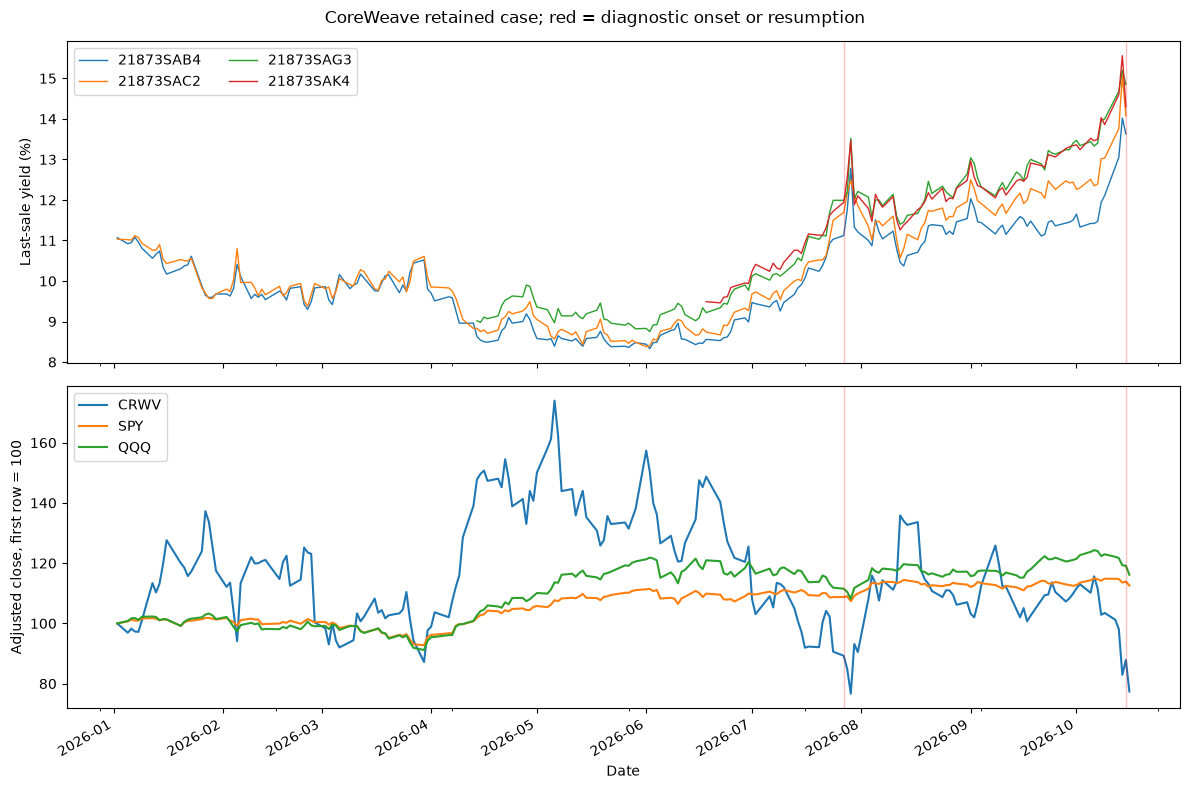

In [5]:
watch=funding_results.loc[funding_results.state=='FUNDING_VULNERABILITY']
print('Issuer:',case['issuer_name'])
print('Earliest loaded funding-watch disclosure:',watch.eligible_at.iloc[0] if len(watch) else 'None in loaded disclosures')
events=timeline.loc[timeline.onset_or_resumption,'date']
print('Diagnostic onsets/resumptions:',[str(x.date()) for x in events])
for row in context.to_dict('records'):
    print('Event:',str(row['date'].date()))
    for h in case['horizons']:
        value=row[f"{case['issuer']}_{h}_sessions_pct"]
        print(f"  Issuer change over {h} observed sessions: {value:+.2f}%" if pd.notna(value) else f"  {h}-session outcome: incomplete")
print('No reliable advance-warning or cross-issuer generalization claim follows from this one selected case.')
import matplotlib.pyplot as plt
fig,axes=plt.subplots(2,1,figsize=(12,8),sharex=True)
for cusip,g in diagnostics.groupby('cusip'):
    axes[0].plot(g.date,g.yield_pct,label=cusip,linewidth=1)
axes[0].set_ylabel('Last-sale yield (%)')
if len(diagnostics): axes[0].legend(ncol=2)
if len(equity): (100*equity/equity.iloc[0]).plot(ax=axes[1])
axes[1].set_ylabel('Adjusted close, first row = 100')
for event in events:
    for ax in axes: ax.axvline(event,color='red',alpha=.25,linewidth=1)
fig.suptitle(case['issuer_name']+' retained case; red = diagnostic onset or resumption')
plt.tight_layout()
plt.show()


## Applying this to future funding-dependent issuers

1. Create a new case with its own issuer identity, instrument ownership evidence, currency, reporting timezone, equity calendar/panel and hash-pinned source snapshot. The shipped case is an example of the contract, not a prediction template.
2. Collect dated financial disclosures, mandatory investment commitments, debt maturity buckets, facility conditions, cash restrictions and successful financing events. Reconcile periods and preserve evidence against the stress hypothesis.
3. Capture issuer and matched-peer OAS with delivery/correction vintages for the stricter credit test. Last-sale yields alone cannot establish issuer-specific credit deterioration. Match currency, maturity, seniority, credit quality and option treatment.
4. Obtain legally usable cash, drawable capacity, monthly receipts/capex/debt service and actual hedge schedules before running a company cash forecast. Capacity, future hedge requirements and annual buckets are not substitutes.
5. Declare exposure rules, costs, false-alarm measures and issuer/period holdouts before outcomes. Compare price-only, broad-credit and issuer-enriched rules on identical coverage. Keep prospective records separately and include failed cases.

The notebook is a research diagnostic, not an automated issuer screening service. None of these inputs is inferred from company resemblance. Missing information remains unknown; one issuer does not establish sector or index stress. The original cash scenarios, portfolio allocations and paper journal are untouched.


In [6]:
from research.credit_funding.model import credit_assessment
strict=credit_assessment([],manifest['created_at'])
print('Original qualified issuer OAS gate:',strict)
print('Frozen baseline:',verify_review_snapshot()['status'])


Original qualified issuer OAS gate: {'asof_utc': '2026-10-17T03:44:28.358154+00:00', 'kind': 'issuer', 'state': 'UNKNOWN', 'reason': 'Insufficient qualified prior history and persistence.', 'observations': 0}
Frozen baseline: VERIFIED_DATED_SNAPSHOT
